# Analysis phase - analysis of terminal processes and how they affect train departure delays from Alnabru

## Data import and format verification

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("mode.string_storage", "python")

df = pd.read_parquet(
    "../data/cleaned_data/combined_cleaned_terminal_dataset.parquet"
)


print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Rows: 5219
Columns: 35


,Merknad,Tognummer,Avgangsdato,Lastefrist,Ferdig opplastet,Frist lok,Lok ankommet,Planlagt klart fra terminal,Klart fra terminal,Planlagt avgangstid - terminal,...,train_id,train_date,cancelled,Planlagt avgangstid - OTR,Faktisk avgangstid - OTR,actual_arrival_time,estimated_arrival_time,just_passing_through,Forsinkelse - OTR,train_company
0,PRI-TOG,5731,2025-08-01,08:50:00,08:45:00,09:02:00,08:30:00,09:37:00,08:58:00,09:42:00,...,5731,2025-08-01,N,09:42:00,09:15:00,<NA>,<NA>,False,-27,CN
1,NaN,5507,2025-08-01,11:40:00,11:40:00,11:43:00,12:00:00,12:18:00,11:30:00,12:23:00,...,5507,2025-08-01,N,12:16:00,12:22:00,<NA>,<NA>,False,6,CN
2,PRI-TOG,41900,2025-08-01,19:35:00,19:30:00,19:46:00,20:00:00,20:21:00,20:00:00,20:26:00,...,<NA>,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,NaN,5709,2025-08-01,20:20:00,20:20:00,20:32:00,20:10:00,21:07:00,20:30:00,21:12:00,...,5709,2025-08-01,N,21:12:00,21:04:00,<NA>,<NA>,False,-8,CN
4,LANGTOG,5515,2025-08-01,21:15:00,21:15:00,21:17:00,20:57:00,21:52:00,21:15:00,21:57:00,...,5515,2025-08-01,N,21:57:00,21:42:00,<NA>,<NA>,False,-15,CN


In [20]:
# Data type for every column
display(df.dtypes.to_frame("Data type"))

# More detailed structural overview
df.info()

,Data type
Merknad,str
Tognummer,string
Avgangsdato,datetime64[us]
Lastefrist,string
Ferdig opplastet,string
Frist lok,string
Lok ankommet,string
Planlagt klart fra terminal,string
Klart fra terminal,string
Planlagt avgangstid - terminal,string


<class 'pandas.DataFrame'>
RangeIndex: 5219 entries, 0 to 5218
Data columns (total 35 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   Merknad                           2189 non-null   str           
 1   Tognummer                         5219 non-null   string        
 2   Avgangsdato                       5219 non-null   datetime64[us]
 3   Lastefrist                        5153 non-null   string        
 4   Ferdig opplastet                  4640 non-null   string        
 5   Frist lok                         5214 non-null   string        
 6   Lok ankommet                      4560 non-null   string        
 7   Planlagt klart fra terminal       5213 non-null   string        
 8   Klart fra terminal                4620 non-null   string        
 9   Planlagt avgangstid - terminal    5212 non-null   string        
 10  Faktisk avgangstid - terminal     4797 non-null   string   

### Preparation of dataset

*Note:* This analysis will not handle possible overnight departures, regardless if they were planned or not. Such departures will be excluded from the analysis, but the limitation is actknowledged.

In [21]:
# Create a clean code-only column as well: keeps only "Txx" from values like "T29 - Andre vinterproblemer"
df["Årsakskode - terminal (kode)"] = (
    df["Årsakskode - terminal"]
    .astype("string")
    .str.strip()
    .str.extract(r"^(T\d+)", expand=False)
    .str.upper()
)

In [ ]:
# --------------------------------------------------
# Identify overnight departures and keep them in a separate dataframe
# --------------------------------------------------
df_overnight_departures = (
    df.loc[
        (
            df["Lastefrist"].notna()
            & df["Planlagt avgangstid - terminal"].notna()
            & df["Faktisk avgangstid - terminal"].notna()
            & (
                pd.to_timedelta(df["Lastefrist"], errors="coerce")
                > pd.to_timedelta(df["Planlagt avgangstid - terminal"], errors="coerce")
            )
            & (
                pd.to_timedelta(df["Lastefrist"], errors="coerce")
                > pd.to_timedelta(df["Faktisk avgangstid - terminal"], errors="coerce")
            )
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("Overnight departures found:", len(df_overnight_departures))
df_overnight_departures[
    [
        "LoggTogID",
        "Avgangsdato",
        "Tognummer",
        "Lastefrist",
        "Planlagt avgangstid - terminal",
        "Faktisk avgangstid - terminal",
    ]
].head()

Overnight departures found: 292


,LoggTogID,Avgangsdato,Tognummer,Lastefrist,Planlagt avgangstid - terminal,Faktisk avgangstid - terminal
0,03-08-2025_5711,2025-08-03,5711,12:00:00,08:12:00,07:19:00
1,18-08-2025_5301,2025-08-18,5301,19:30:00,08:51:00,07:51:00
2,01-09-2025_5301,2025-09-01,5301,19:30:00,08:51:00,09:20:00
3,08-09-2025_5301,2025-09-08,5301,19:30:00,08:51:00,08:49:00
4,15-09-2025_5301,2025-09-15,5301,19:30:00,08:51:00,08:58:00


In [24]:
# --------------------------------------------------
# Discard overnight records from the main dataframe
# --------------------------------------------------
overnight_logg_ids = df_overnight_departures["LoggTogID"].dropna().unique()

mask = ~df["LoggTogID"].isin(overnight_logg_ids)

df = df.loc[mask].copy().reset_index(drop=True)

print("Rows left after removal:", len(df))

Rows left after removal: 4927


## Actual analysis

*Note:* In the define phase, there was made a discovery that the winter operations vary a lot compared to the summer season. Because of that, there will first be done an analysis for the whole year, then the summer season (mar-nov), and then the winter season (dec-feb)

### Årsakskode-mapping
To have as a visual reference throughout

In [25]:
df_aarsakskodeliste = pd.read_csv("../data/Årsakskodelister (IKKE REDIGER!.csv", sep=";", encoding="utf-8-sig")

df_aarsakskodeliste

,Kode,Kort beskrivelse,Nedtrekks-tekst,Tilhørende YtelsesordningKode
0,T1,I rute,T1 - I rute,NaN
1,T2,Nytt tognummer (Skriv det nye i kommentar),T2 - Nytt tognummer (Skriv det nye i kommentar),Kode 7 - Trafikkavvikling (Infrastrukturs andel)
2,T3,Lokfører,T3 - Lokfører,Kode 83 - Manglende personell
3,T4,Forsinket ankommet tog. (kort snutid),T4 - Forsinket ankommet tog. (kort snutid),Kode 82 - Kjøretøy sent fra hensettingsspor
4,T5,Vognmangel,T5 - Vognmangel,Kode 85 - Planforutsetninger ikke oppfylt
5,T6,De-icing,T6 - De-icing,Kode 85 - Planforutsetninger ikke oppfylt
6,T7,Graving av snø,T7 - Graving av snø,Kode 92 - Ytre forhold
7,T8,Maskinmangel skifting,T8 - Maskinmangel skifting,Kode 84 - Stasjonsopphold
8,T9,Feil på vogn,T9 - Feil på vogn,Kode 81 - Feil ved kjøretøy
9,T10,Overbooking,T10 - Overbooking,Kode 85 - Planforutsetninger ikke oppfylt


### Whole year analysis

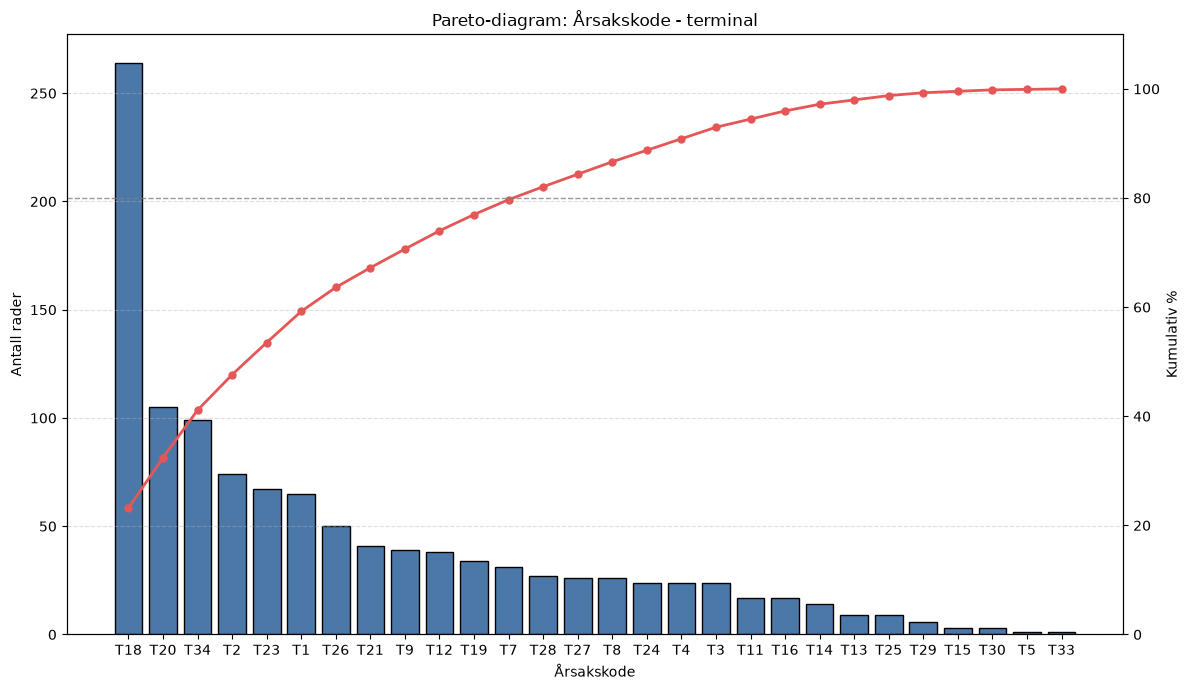

Total rows with a code: 1138

Top coded causes:
Årsakskode - terminal (kode)
T18    23.20
T20     9.23
T34     8.70
T2      6.50
T23     5.89
T1      5.71
T26     4.39
T21     3.60
T9      3.43
T12     3.34
T19     2.99
T7      2.72
T28     2.37
T27     2.28
T8      2.28
T24     2.11
T4      2.11
T3      2.11
T11     1.49
T16     1.49
T14     1.23
T13     0.79
T25     0.79
T29     0.53
T15     0.26
T30     0.26
T5      0.09
T33     0.09


In [ ]:
# Use the new code column for the Pareto analysis
code_col = "Årsakskode - terminal (kode)"

# Keep only rows with a code
codes = df[code_col].dropna().astype(str).str.strip()
codes = codes[codes != ""]

# Count occurrences
code_counts = codes.value_counts().sort_values(ascending=False)

# Total number of coded rows
total_with_code = code_counts.sum()

# Proportion and cumulative share
share_pct = (code_counts / total_with_code) * 100
cum_pct = share_pct.cumsum()

# Optional: limit to top custom codes to avoid clutter
code_counts = code_counts.head(40)
share_pct = share_pct.loc[code_counts.index]
cum_pct = cum_pct.loc[code_counts.index]

# Plot
fig, ax1 = plt.subplots(figsize=(12, 7))

bars = ax1.bar(
    code_counts.index,
    code_counts.values,
    color="#4C78A8",
    edgecolor="black"
)

ax1.set_title("Pareto-diagram: Årsakskode - terminal")
ax1.set_xlabel("Årsakskode")
ax1.set_ylabel("Antall rader")
ax1.grid(axis="y", linestyle="--", alpha=0.4)

# Cumulative percentage on secondary axis
ax2 = ax1.twinx()
ax2.plot(
    code_counts.index,
    cum_pct.values,
    color="#E45756",
    marker="o",
    linewidth=2,
    markersize=5,
    label="Kumulativ %"
)
ax2.set_ylabel("Kumulativ %")
ax2.set_ylim(0, 110)

# Optional: 80% line
ax2.axhline(80, linestyle="--", color="gray", linewidth=1, alpha=0.8)

# Keep x-labels readable
ax1.tick_params(axis="x", rotation=0)
ax1.set_xticks(range(len(code_counts.index)))
ax1.set_xticklabels(code_counts.index)

plt.tight_layout()
plt.show()

print(f"Total rows with a code: {total_with_code}")
print("\nTop coded causes:")
print(share_pct.round(2).to_string())

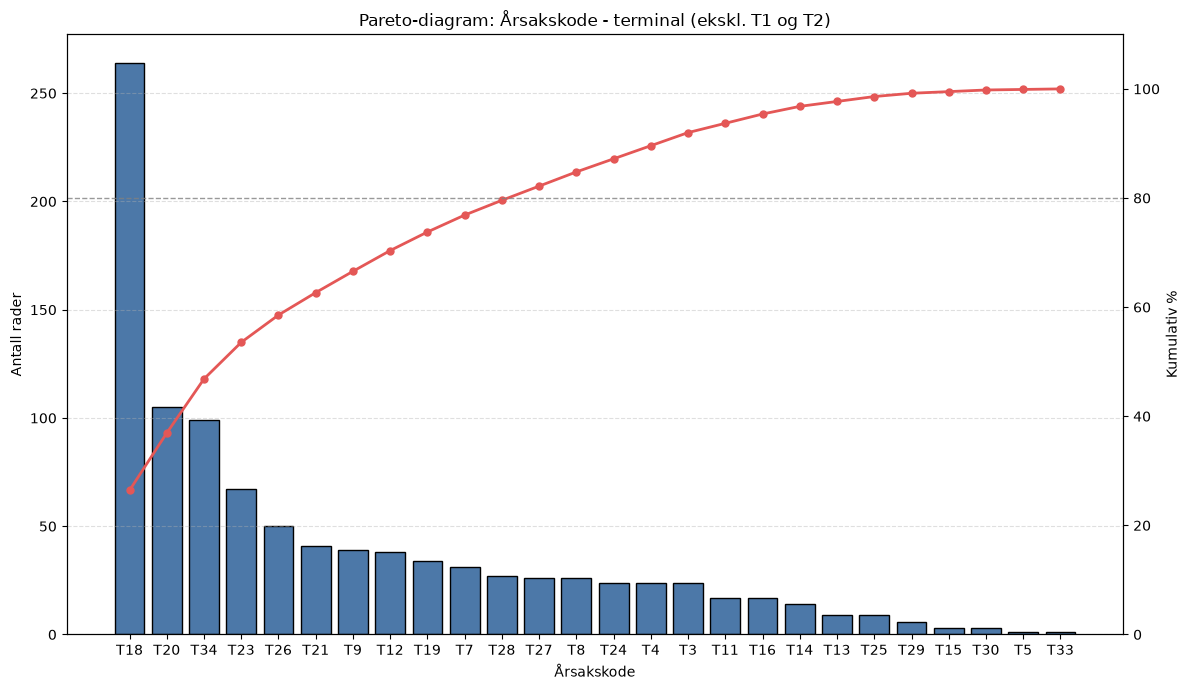

Total rows with a code after excluding T1 and T2: 999

Top codes after exclusion:
Årsakskode - terminal (kode)
T18    26.43
T20    10.51
T34     9.91
T23     6.71
T26     5.01
T21      4.1
T9       3.9
T12      3.8
T19      3.4
T7       3.1
T28      2.7
T27      2.6
T8       2.6
T24      2.4
T4       2.4
T3       2.4
T11      1.7
T16      1.7
T14      1.4
T13      0.9
T25      0.9
T29      0.6
T15      0.3
T30      0.3
T5       0.1
T33      0.1


In [27]:
# 2) Exclude T1 and T2 before analysis
excluded_codes = {"T1", "T2"}

df_aarsakskodeliste = df[
    df["Årsakskode - terminal (kode)"].notna() &
    ~df["Årsakskode - terminal (kode)"].isin(excluded_codes)
].copy()

# 3) Count only remaining codes
code_counts = (
    df_aarsakskodeliste["Årsakskode - terminal (kode)"]
    .value_counts()
    .sort_values(ascending=False)
)

# Optional: limit to the top N to reduce clutter
code_counts = code_counts.head(35)

# 4) Calculate total rows with valid codes after exclusion
total_with_code = code_counts.sum()

# 5) Calculate share and cumulative share
share_pct = (code_counts / total_with_code) * 100
cum_pct = share_pct.cumsum()

# 6) Plot Pareto chart
fig, ax1 = plt.subplots(figsize=(12, 7))

ax1.bar(code_counts.index, code_counts.values, color="#4C78A8", edgecolor="black")
ax1.set_title("Pareto-diagram: Årsakskode - terminal (ekskl. T1 og T2)")
ax1.set_xlabel("Årsakskode")
ax1.set_ylabel("Antall rader")
ax1.grid(axis="y", linestyle="--", alpha=0.4)

ax2 = ax1.twinx()
ax2.plot(code_counts.index, cum_pct.values, color="#E45756", marker="o",
         linewidth=2, markersize=5, label="Kumulativ %")
ax2.set_ylabel("Kumulativ %")
ax2.set_ylim(0, 110)

ax2.axhline(80, linestyle="--", color="gray", linewidth=1, alpha=0.8)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"Total rows with a code after excluding T1 and T2: {total_with_code}")
print("\nTop codes after exclusion:")
print(share_pct.round(2).to_string())

### Summer season analysis

### Winter season analysis